# Atividade Final — Aprendizado de Máquina I: Investigação do Algoritmo LightGBM (*Light Gradient Boosting Machine*)

**Instituição:** FATEC Jundiaí — Faculdade de Tecnologia Deputado Ary Fossen  
**Curso:** Tecnologia em Ciência de Dados  
**Disciplina:** Aprendizado de Máquina I  
**Professor:** Prof. Me. Mateus Guilherme Fuini  
**Aluno:** Rodolfo Vinicius Cima Takemoto  
**Modalidade Escolhida:** Modalidade A — Investigação de uma Técnica de Machine Learning  

---

## Sumário Estruturado (Alinhado ao Edital e ao Checklist de Projetos de ML)

1. **Seção 1 — Introdução:** Apresentação do **LightGBM**, motivação histórica, finalidade e problemas que resolve em ciência de dados tabulares.
2. **Seção 2 — Fundamentação Teórica e Matemática:** Diferença entre *Bagging* e *Gradient Boosting*, aproximação de Taylor de segunda ordem, discretização por histogramas, *Gradient-based One-Side Sampling* (GOSS), *Exclusive Feature Bundling* (EFB), crescimento *leaf-wise* vs. *level-wise* e principais hiperparâmetros.
3. **Seção 3 — Aplicações Práticas e Formulação do Problema de Negócio:** Aplicações reais na indústria e modelagem do problema de **Predição de Inadimplência de Crédito Bancário (*Credit Default Risk*)** com matriz de custos assimétricos ($\text{FN} = \text{R\$ } 8.500,00$ vs. $\text{FP} = \text{R\$ } 450,00$).
4. **Seção 4 — Implementação em Python (EDA, Prevenção de *Data Leakage* e Baselines):**
   - 4.1. Construção/carregamento determinístico da carteira de crédito (`N = 5.000`), inspeção de tipos, valores ausentes e *outliers*.
   - 4.2. Análise Exploratória de Dados (EDA) com diagnóstico visual de desbalanceamento (`78,0%` vs. `22,0%`) e assimetria.
   - 4.3. Divisão estratificada (`Treino = 3.500`, `Validação = 750`, `Teste Oficial = 750`) **antes** do pré-processamento e construção de `Pipeline` + `ColumnTransformer` livre de vazamento de dados (*data leakage*).
   - 4.4. Comparação inicial entre Baselines (`DummyClassifier`) e `LGBMClassifier` via Validação Cruzada Estratificada (`5-Fold CV`).
5. **Seção 5 — Experimentação Controlada (Três Experimentos):**
   - **Experimento 1 (Controle de Complexidade *Leaf-Wise* e Trade-off Viés × Variância):** Variação conjunta de `num_leaves`, `max_depth`, `min_child_samples` e `learning_rate`, medindo o *gap* de generalização ($\text{Treino} - \text{Validação}$).
   - **Experimento 2 (Sensibilidade à Escala de Atributos e Outliers):** Comparação entre dados brutos (`Sem Escala`), `MinMaxScaler` e `StandardScaler` sobre `K-NN`, `SVM (RBF)`, `Random Forest` e `LightGBM`.
   - **Experimento 3 (Desbalanceamento de Classes e Calibração do Limiar de Decisão por Custo Financeiro):** Comparação entre `scale_pos_weight` e otimização do limiar de probabilidade $p^*$ para minimizar o prejuízo financeiro da carteira.
6. **Seção 6 — Avaliação Comparativa Final no Conjunto de Teste Oficial:** Confronto definitivo entre **7 modelos** (`Dummy Baseline`, `Naive Bayes`, `K-NN`, `Árvore de Decisão`, `Random Forest`, `SVM RBF` e `LightGBM Otimizado`) usando Accuracy, Precision, Recall, F1-Score, ROC-AUC, Curvas ROC, Importância de Variáveis, Tempo de Treino e Custo Financeiro.
7. **Seção 7 — Análise Crítica:** Vantagens, limitações e quadro comparativo direto entre o **LightGBM** e os algoritmos estudados na disciplina.
8. **Seção 8 — Conclusão, Referências Bibliográficas e Relato de Uso de IA.**

## 1. Introdução

Ao longo da disciplina de **Aprendizado de Máquina I**, estudamos algoritmos fundamentais de aprendizado supervisionado e não supervisionado: métodos baseados em distância (**K-NN** e **K-Means**), modelos probabilísticos (**Naive Bayes**), máquinas de margem máxima e *kernels* (**SVM**) e métodos baseados em árvores de decisão e *ensembles* por **Bagging** (**Árvore de Decisão** e **Random Forest**).

No contexto de **Random Forest**, vimos que o paradigma de **Bagging (*Bootstrap Aggregating*)** constrói dezenas ou centenas de árvores de decisão **independentes e em paralelo**, cada uma treinada sobre uma amostra *bootstrap* dos dados e considerando um subconjunto aleatório de atributos (`max_features`) em cada nó. O objetivo primordial do *Bagging* é **reduzir a variância** de árvores profundas sem aumentar seu viés, agregando suas previsões por votação majoritária.

Entretanto, existe uma segunda família de *ensembles* de árvores que domina problemas de dados tabulares estruturados em aplicações industriais e competições científicas: o **Gradient Boosting Decision Trees (GBDT)**. Diferentemente do *Bagging*, o **Boosting** constrói árvores **de forma sequencial e aditiva**, onde cada nova árvore não tenta prever o rótulo original isoladamente, mas sim **corrigir os erros residuais (pseudo-resíduos ou gradientes negativos da função de perda)** deixados pelo conjunto das árvores anteriores. Dessa forma, o *Boosting* atua primordialmente na **redução do viés** do modelo, combinando múltiplos aprendizes fracos (*weak learners* — árvores rasas e regularizadas) em um preditor forte.

### O que é o LightGBM e que problema ele resolve?

Proposto por **Guolin Ke et al. (2017)** na conferência *Advances in Neural Information Processing Systems (NeurIPS)* pela equipe da **Microsoft Research**, o **LightGBM (*Light Gradient Boosting Machine*)** é uma implementação de *Gradient Boosting* de alta eficiência projetada para resolver o principal gargalo dos algoritmos tradicionais de GBDT (como o `GradientBoostingClassifier` clássico do Scikit-learn e o XGBoost original por ordenação exata):

1. **Gargalo computacional do GBDT clássico:** Para encontrar o melhor ponto de divisão (*split*) em cada nó de uma árvore, os algoritmos tradicionais precisavam ordenar todos os $N$ exemplos para cada um dos $d$ atributos contínuos (*pre-sorted algorithm*), resultando em um custo de tempo e memória de ordem $O(N \times d)$ por nível da árvore. Em bases com dezenas de milhares de registros e dezenas de variáveis, esse processo torna o treinamento lento e intensivo em RAM.
2. **Solução proposta pelo LightGBM:** O LightGBM introduz a **discretização baseada em histogramas** ($O(B \times d)$, onde $B \le 255$ *bins*), combinada com duas técnicas inéditas — **GOSS (*Gradient-based One-Side Sampling*)** e **EFB (*Exclusive Feature Bundling*)** — além da estratégia de crescimento de árvore **orientada à folha (*leaf-wise* / *best-first*)**. Com isso, o LightGBM reduz o tempo de treinamento em até **10 a 20 vezes** e o consumo de memória em mais de **5 vezes**, mantendo ou superando a capacidade preditiva dos demais métodos tabulares.

## 2. Fundamentação Teórica e Matemática

### 2.1. Formulação Aditiva do Gradient Boosting e Aproximação de Segunda Ordem

Considere um conjunto de treinamento $\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^{N}$, com $\mathbf{x}_i \in \mathbb{R}^d$ e $y_i \in \{0, 1\}$. Um modelo de *Gradient Boosting* com $M$ árvores constrói a predição em escala de *log-odds* (logits) $\hat{y}_i^{(M)} = F_M(\mathbf{x}_i)$ de maneira aditiva:

$$F_m(\mathbf{x}_i) = F_{m-1}(\mathbf{x}_i) + \eta \cdot h_m(\mathbf{x}_i), \qquad m = 1, 2, \dots, M$$

onde $h_m(\mathbf{x})$ é a $m$-ésima árvore de regressão ajustada na iteração $m$ e $\eta \in (0, 1]$ é a **taxa de aprendizado (*learning rate* ou *shrinkage*)**, que controla a contribuição individual de cada árvore para evitar superajuste (*overfitting*). A probabilidade estimada para a classe positiva ($y_i = 1$) é obtida aplicando a função logística (sigmoide):

$$p_i^{(m-1)} = \sigma\left(F_{m-1}(\mathbf{x}_i)\right) = \frac{1}{1 + e^{-F_{m-1}(\mathbf{x}_i)}}$$

Para otimizar a função objetivo regularizada na etapa $m$:

$$\mathcal{Obj}^{(m)} = \sum_{i=1}^{N} \mathcal{L}\left(y_i, F_{m-1}(\mathbf{x}_i) + h_m(\mathbf{x}_i)\right) + \Omega(h_m), \qquad \text{com } \Omega(h_m) = \gamma J + \alpha \sum_{j=1}^{J} |w_j| + \frac{1}{2}\lambda \sum_{j=1}^{J} w_j^2$$

o LightGBM expande a perda $\mathcal{L}$ (no caso binário, a *Binary Log-Loss*) por **Série de Taylor de segunda ordem** em torno de $F_{m-1}(\mathbf{x}_i)$, calculando para cada instância $i$ o **gradiente de primeira ordem ($g_i$)** e a **hessiana de segunda ordem ($h_i$)**:

$$g_i = \frac{\partial \mathcal{L}(y_i, \hat{y}_i^{(m-1)})}{\partial \hat{y}_i^{(m-1)}} = p_i^{(m-1)} - y_i, \qquad h_i = \frac{\partial^2 \mathcal{L}(y_i, \hat{y}_i^{(m-1)})}{\partial (\hat{y}_i^{(m-1)})^2} = p_i^{(m-1)}\left(1 - p_i^{(m-1)}\right)$$

Agrupando as instâncias que caem na folha $j$ ($I_j = \{i : q(\mathbf{x}_i) = j\}$) e definindo $G_j = \sum_{i \in I_j} g_i$ e $H_j = \sum_{i \in I_j} h_i$, o peso ótimo $w_j^*$ da folha $j$ (com regularização $L_2 = \lambda$) e o **Ganho de Divisão (*Split Gain*)** ao dividir um nó pai em filho esquerdo ($L$) e filho direito ($R$) são dados por:

$$w_j^* = -\frac{G_j}{H_j + \lambda}, \qquad \mathcal{G}_{\text{split}} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\right] - \gamma$$

---

### 2.2. Os Três Pilares de Eficiência do LightGBM (Ke et al., 2017)

1. **Algoritmo Baseado em Histogramas e Subtração de Histogramas (*Histogram Subtraction*):**
   - Antes do treinamento, os valores contínuos de cada atributo são agrupados em $B$ intervalos discretos (*bins*, por padrão `max_bin = 255`, armazenáveis em apenas 1 byte `uint8` por valor).
   - Em cada nó, o algoritmo acumula as somas de gradientes ($G$) e hessianas ($H$) dentro dos $B$ *bins*, reduzindo o custo de busca de $O(N \times d)$ para $O(B \times d)$.
   - Além disso, o histograma do nó filho com mais amostras é obtido **subtraindo** o histograma do irmão menor do histograma do nó pai ($\text{Hist}(\text{Filho Maior}) = \text{Hist}(\text{Pai}) - \text{Hist}(\text{Filho Menor})$) em tempo $O(B)$.

2. **GOSS (*Gradient-based One-Side Sampling*):**
   - No *Gradient Boosting*, instâncias com $|g_i|$ pequeno já estão bem classificadas (resíduo próximo de zero), enquanto instâncias com $|g_i|$ grande estão na região de erro e carregam a maior parte do ganho de informação.
   - O GOSS ordena as instâncias por $|g_i|$, mantém os $a \times 100\%$ exemplos de maior gradiente e sorteia aleatoriamente $b \times 100\%$ dos exemplos restantes de pequeno gradiente, multiplicando os gradientes deste segundo grupo pelo fator $\frac{1-a}{b}$ para não alterar a distribuição estatística da população.

3. **EFB (*Exclusive Feature Bundling*):**
   - Em bases tabulares com variáveis categóricas codificadas (*one-hot encoding*) ou atributos esparsos, muitas colunas nunca assumem valores não nulos simultaneamente (são mutuamente exclusivas).
   - O EFB modela essa relação como um problema de coloração de grafos e funde atributos mutuamente exclusivos em um único *bundle* deslocando os intervalos de seus *bins*, reduzindo drasticamente o número efetivo de colunas $d$.

---

### 2.3. Crescimento *Leaf-Wise* (*Best-First*) vs. *Level-Wise* (*Depth-First*)

* **Crescimento *Level-Wise* (usado em Árvores tradicionais e XGBoost clássico):** Divide simultaneamente **todos os nós de uma mesma profundidade** antes de avançar para o próximo nível, mesmo que vários nós tenham baixo ganho de informação. Produz árvores simétricas e balanceadas.
* **Crescimento *Leaf-Wise* (adotado pelo LightGBM):** Entre todas as folhas existentes na árvore atual, o LightGBM escolhe expandir **exclusivamente a folha que proporciona o maior ganho $\mathcal{G}_{\text{split}}$**.
  - **Vantagem:** Para um mesmo número de folhas, o crescimento *leaf-wise* atinge perda de treinamento significativamente menor que o *level-wise*.
  - **Risco e Controle:** Se `num_leaves` for muito alto e `max_depth` for irrestrito (`-1`), o crescimento *leaf-wise* pode criar ramos muito profundos e específicos para poucos exemplos, gerando **overfitting** (alta variância). Por isso, a documentação técnica recomenda combinar `max_depth` com a restrição:
    $$\text{num\_leaves} < 2^{\text{max\_depth}}$$
    aliada a um piso mínimo de amostras por folha (`min_child_samples`).

---

### 2.4. Principais Hiperparâmetros do LightGBM

| Hiperparâmetro (`LGBMClassifier`) | Papel Algorítmico | Efeito no Trade-off Viés × Variância |
| :--- | :--- | :--- |
| **`num_leaves`** (padrão `31`) | Número máximo de folhas por árvore base (*leaf-wise*). | Parâmetro principal de complexidade: valores altos reduzem viés mas elevam fortemente a variância (*overfitting*). |
| **`max_depth`** (padrão `-1`) | Profundidade máxima permitida para qualquer ramo da árvore. | Limita o aprofundamento unilateral do *leaf-wise*; valores entre `3` e `6` previnem memorização em bases médias. |
| **`learning_rate`** ($\eta$, padrão `0.1`) | Taxa de encolhimento (*shrinkage*) aplicada a cada árvore. | Valores menores (`0.03` a `0.05`) exigem mais árvores (`n_estimators`), mas suavizam a fronteira de decisão e melhoram a generalização. |
| **`n_estimators`** (padrão `100`) | Número total de árvores sequenciais de *boosting* ($M$). | Mais árvores reduzem o erro de treino; em excesso (sem regularização ou *early stopping*), aumentam o *gap* treino-validação. |
| **`min_child_samples`** (padrão `20`) | Número mínimo de registros exigido para criar uma folha. | Equivalente ao `min_samples_leaf` visto na aula de Árvores: impede folhas que isolam ruído ou *outliers* individuais. |
| **`subsample`** / **`colsample_bytree`** | Fração de linhas e de colunas amostradas por árvore. | Introduz aleatoriedade análoga à *Random Forest*, descorrelacionando as árvores sequenciais e reduzindo variância. |
| **`reg_alpha`** ($L_1$) / **`reg_lambda`** ($L_2$) | Penalidades de regularização sobre os pesos $w_j$ das folhas. | Encolhem os logits das folhas ($w_j^* = -G_j / (H_j + \lambda)$), tornando as previsões de probabilidade mais conservadoras. |
| **`scale_pos_weight`** (padrão `1.0`) | Multiplicador de peso aplicado aos gradientes da classe positiva. | Essencial em bases desbalanceadas ($\approx N_{\text{neg}} / N_{\text{pos}}$): aumenta a penalidade dos Falsos Negativos, elevando o *Recall*. |

## 3. Aplicações Práticas e Formulação do Problema de Negócio

### 3.1. Onde o LightGBM é Utilizado no Mundo Real?

Devido à sua velocidade de treinamento, baixo uso de memória e alta acurácia em dados tabulares heterogêneos (mistura de variáveis contínuas assimétricas, contagens discretas e atributos categóricos), o LightGBM é amplamente utilizado em produção em:

1. **Risco de Crédito e *Credit Scoring* (Bancos e Fintechs):** Concessão automatizada de empréstimos pessoais, financiamento imobiliário e definição de limite de cartão de crédito, estimando a Probabilidade de Inadimplência (*Probability of Default — PD*).
2. **Prevenção a Fraudes em Meios de Pagamento:** Classificação em tempo real (latência sub-milissegundo) de transações de cartão e PIX com forte desbalanceamento entre transações legítimas e fraudulentas.
3. **Retenção de Clientes (*Customer Churn Prediction*):** Identificação preventiva de clientes com alta propensão ao cancelamento em operadoras de telecomunicações, bancos digitais e plataformas de assinatura (SaaS).
4. **Varejo e Logística:** Previsão de demanda de estoque SKU-a-SKU (como demonstrado na competição global *M5 Forecasting* do Walmart, na qual as soluções vencedoras basearam-se em LightGBM) e estimativa de tempo de entrega (*ETA*).
5. **Saúde e Indústria:** Triagem clínica baseada em exames laboratoriais tabulares e manutenção preditiva de equipamentos industriais.

---

### 3.2. Definição do Caso de Estudo deste Trabalho: Risco de Inadimplência Bancária

Seguindo o **Checklist de Projetos de Machine Learning** apresentado nas aulas do Prof. Mateus Fuini, iniciamos pela definição clara do problema e da métrica orientada ao negócio:

* **Contexto:** Uma instituição financeira deseja automatizar a análise de concessão de crédito pessoal a partir do histórico de **5.000 contratos** com **12 variáveis cadastrais, financeiras e comportamentais**.
* **Variável-Alvo (`inadimplente`):**
  * `0` (**Adimplente — 78,0% da carteira**): Cliente que honrou integralmente as parcelas nos primeiros 12 meses após a concessão.
  * `1` (**Inadimplente — 22,0% da carteira**): Cliente que incorreu em atraso superior a 90 dias (*default* bancário).
* **Assimetria do Custo dos Erros (Conexão direta com a Aula 02 — Métricas de Avaliação):**
  * **Falso Negativo ($\text{FN}$ — Aprovar automaticamente um cliente que se tornará inadimplente):** Gera perda direta de capital emprestado líquida de recuperação judicial, estimada pela controladoria do banco em **$\text{Custo}_{\text{FN}} = \text{R\$ } 8.500,00$** por contrato.
  * **Falso Positivo ($\text{FP}$ — Classificar um bom pagador como alto risco):** O pedido é encaminhado para revisão manual em mesa de crédito ou recebe exigência de garantia adicional, gerando um custo operacional e de oportunidade médio de **$\text{Custo}_{\text{FP}} = \text{R\$ } 450,00$** por contrato.
  * **Verdadeiro Positivo ($\text{VP}$) e Verdadeiro Negativo ($\text{VN}$):** Decisões corretas ($\text{Custo} = \text{R\$ } 0,00$).
* **Função de Custo Financeiro Total da Carteira Avaliada:**
  $$\text{Custo Total (R\$)} = 8.500 \times \text{FN} + 450 \times \text{FP}$$
* **Por que a Acurácia não basta?** Um modelo ingênuo (*Baseline*) que aprove 100% dos clientes alcança **78,00% de Acurácia**, mas deixa passar **100% dos inadimplentes ($\text{Recall} = 0,0\%$)**, causando prejuízo milionário. Portanto, avaliaremos conjuntamente **ROC-AUC**, **F1-Score**, **Recall da classe positiva**, **Precision** e o **Custo Financeiro Total em R\$**.

## 4. Implementação em Python: Ambiente, Dados, EDA e Pipeline Livre de *Data Leakage*

Nesta seção, preparamos o ambiente computacional, construímos/carregamos o conjunto de dados de risco de crédito de maneira 100% determinística (`SEED = 42`), realizamos a **Análise Exploratória de Dados (EDA)** nos moldes da *Aula 01* e implementamos o fluxo de pré-processamento encapsulado em `Pipeline` + `ColumnTransformer` conforme as boas práticas das *Aulas 03 e 04*.

In [1]:
# Instalacao automatica do LightGBM caso executado no Google Colab ou ambiente sem o pacote
import subprocess, sys
try:
    import lightgbm as lgb
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lightgbm"])
    import lightgbm as lgb

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import __version__ as sklearn_version
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve, classification_report
)
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print(f"Ambiente configurado com sucesso! SEED = {SEED}")
print(f"Python: {sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__}")
print(f"Scikit-Learn: {sklearn_version} | LightGBM: {lgb.__version__}")

Ambiente configurado com sucesso! SEED = 42
Python: 3.11.9 | NumPy: 1.26.4 | Pandas: 2.2.2
Scikit-Learn: 1.5.2 | LightGBM: 4.5.0


### 4.1. Conjunto de Dados e Dicionário de Variáveis

Para garantir **reprodutibilidade total em qualquer ambiente** (Google Colab ou execução local sem dependência de links externos quebrados) e refletir fielmente os desafios reais encontrados em modelagem de crédito bancário, o conjunto de dados **`df_credito` (`N = 5.000` clientes)** possui:
* **Desbalanceamento realista:** `78,00%` de clientes adimplentes (`3.900`) e `22,00%` de inadimplentes (`1.100`).
* **Diferentes ordens de grandeza e *outliers* (assimetria positiva):** Variáveis em reais (`renda_mensal` chegando a R\$ 42 mil e `valor_emprestimo` chegando a R\$ 145 mil) coexistem com razões no intervalo $[0, 1]$ (`comprometimento_renda` e `utilizacao_rotativo`), permitindo testar na prática o efeito da escala estudado na **Aula 04**.
* **Valores ausentes (*missing values*):** Presença de `2,50%` de valores ausentes em `renda_mensal` (`125` registros) e `1,80%` em `tempo_emprego_anos` (`90` registros), exigindo imputação estatística livre de vazamento.
* **Interações não lineares de limiar:** O risco de inadimplência cresce de forma não linear quando `qtd_atrasos_12m >= 2` combina-se com `comprometimento_renda > 0.45` e `score_bureau < 560`.

| Variável | Tipo | Descrição de Negócio e Escala |
| :--- | :---: | :--- |
| `idade` | Numérica | Idade do solicitante em anos (`21` a `74` anos). |
| `renda_mensal` | Numérica | Renda mensal comprovada em R\$ (`1.200` a `42.500`), distribuição log-normal com *outliers* e `2,5%` de *missing*. |
| `tempo_emprego_anos` | Numérica | Tempo de vínculo profissional atual em anos (`0,0` a `35,0`), com `1,8%` de *missing*. |
| `valor_emprestimo` | Numérica | Montante total solicitado no contrato em R\$ (`2.500` a `145.000`). |
| `taxa_juros_anual` | Numérica | Taxa efetiva anual do contrato em `% a.a.` (`11,5%` a `68,0%`). |
| `comprometimento_renda` | Numérica | Fração da renda mensal comprometida com dívidas (`0,05` a `0,88`). |
| `score_bureau` | Numérica | Pontuação de bureau de crédito externo (`300` a `950` pontos). |
| `utilizacao_rotativo` | Numérica | Taxa de utilização do limite de crédito rotativo/cartão (`0,00` a `1,00`). |
| `qtd_atrasos_12m` | Numérica | Quantidade de atrasos entre 15 e 60 dias nos últimos 12 meses (`0` a `7`). |
| `qtd_consultas_6m` | Numérica | Consultas ao CPF em bureaus nos últimos 6 meses (`0` a `9`). |
| `tipo_moradia` | Categórica | Situação habitacional (`Propria`, `Alugada`, `Financiada`, `Familiar`). |
| `finalidade_credito` | Categórica | Destino declarado do empréstimo (`Quitacao_Dividas`, `Reforma`, `Veiculo`, `Educacao`, `Capital_Giro`). |
| **`inadimplente`** | **Alvo (`0`/`1`)** | **`0` = Adimplente (`3.900` / `78,0%`)** \| **`1` = Inadimplente (`1.100` / `22,0%`)**. |

In [2]:
def gerar_carteira_credito_bancario(n_samples=5000, seed=42):
    rng = np.random.default_rng(seed)
    idade = rng.integers(21, 75, size=n_samples).astype(float)
    # Renda mensal log-normal com cauda longa (outliers de alta renda)
    renda_mensal = np.round(rng.lognormal(mean=8.65, sigma=0.58, size=n_samples), 2)
    renda_mensal = np.clip(renda_mensal, 1200.0, 42500.0)
    tempo_emprego = np.round(np.clip(rng.exponential(scale=5.8, size=n_samples), 0.0, np.maximum(0.0, idade - 18.0)), 1)
    score_bureau = np.round(np.clip(rng.normal(loc=635, scale=110, size=n_samples), 300, 950), 0)
    utilizacao_rotativo = np.round(rng.beta(a=2.1, b=3.2, size=n_samples), 4)
    qtd_atrasos_12m = rng.poisson(lam=np.where(score_bureau < 560, 1.45, 0.35), size=n_samples)
    qtd_atrasos_12m = np.clip(qtd_atrasos_12m, 0, 7)
    qtd_consultas_6m = np.clip(rng.poisson(lam=1.3, size=n_samples), 0, 9)
    comprometimento_renda = np.round(np.clip(rng.normal(0.33, 0.15, size=n_samples) + 0.12 * utilizacao_rotativo, 0.05, 0.88), 4)
    valor_emprestimo = np.round(np.clip(renda_mensal * rng.uniform(1.8, 6.2, size=n_samples), 2500.0, 145000.0), 2)
    taxa_juros_anual = np.round(np.clip(48.0 - 0.032 * (score_bureau - 300) + 3.1 * qtd_atrasos_12m + rng.normal(0, 3.0, size=n_samples), 11.5, 68.0), 2)

    tipo_moradia = rng.choice(["Propria", "Alugada", "Financiada", "Familiar"], size=n_samples, p=[0.38, 0.34, 0.18, 0.10])
    finalidade_credito = rng.choice(["Quitacao_Dividas", "Reforma", "Veiculo", "Educacao", "Capital_Giro"], size=n_samples, p=[0.36, 0.20, 0.18, 0.12, 0.14])

    # Mecanismo gerador latente com interacoes nao lineares de limiar (tipicas de risco de credito)
    logit_risco = (
        -2.35
        + 0.88 * qtd_atrasos_12m
        - 0.0085 * (score_bureau - 600)
        + 3.40 * (comprometimento_renda - 0.35)
        + 1.65 * (utilizacao_rotativo - 0.45)
        + 0.035 * (taxa_juros_anual - 28.0)
        - 0.000045 * (renda_mensal - 6000.0)
        + 0.85 * ((qtd_atrasos_12m >= 2) & (comprometimento_renda > 0.42)).astype(float)
        + 0.70 * ((score_bureau < 540) & (utilizacao_rotativo > 0.65)).astype(float)
        + np.where(tipo_moradia == "Alugada", 0.35, 0.0)
        + np.where(finalidade_credito == "Quitacao_Dividas", 0.42, 0.0)
        + rng.normal(0.0, 0.55, size=n_samples)
    )
    # Calibrar exatamente 22.0% de inadimplentes (1.100 contratos de 5.000)
    limiar_quantil = np.quantile(logit_risco, 0.78)
    inadimplente = (logit_risco >= limiar_quantil).astype(int)

    df = pd.DataFrame({
        "idade": idade,
        "renda_mensal": renda_mensal,
        "tempo_emprego_anos": tempo_emprego,
        "valor_emprestimo": valor_emprestimo,
        "taxa_juros_anual": taxa_juros_anual,
        "comprometimento_renda": comprometimento_renda,
        "score_bureau": score_bureau,
        "utilizacao_rotativo": utilizacao_rotativo,
        "qtd_atrasos_12m": qtd_atrasos_12m,
        "qtd_consultas_6m": qtd_consultas_6m,
        "tipo_moradia": tipo_moradia,
        "finalidade_credito": finalidade_credito,
        "inadimplente": inadimplente
    })
    # Inserir valores ausentes realistas (MCAR/MAR): 2.5% em renda_mensal e 1.8% em tempo_emprego_anos
    idx_na_renda = rng.choice(n_samples, size=125, replace=False)
    idx_na_emp   = rng.choice(n_samples, size=90, replace=False)
    df.loc[idx_na_renda, "renda_mensal"] = np.nan
    df.loc[idx_na_emp, "tempo_emprego_anos"] = np.nan
    return df

df_credito = gerar_carteira_credito_bancario(n_samples=5000, seed=SEED)
print(f"Dimensoes do Dataset: {df_credito.shape[0]} linhas x {df_credito.shape[1]} colunas")
print("\nDistribuicao da Variavel-Alvo (inadimplente):")
contagem = df_credito["inadimplente"].value_counts().sort_index()
for k, v in contagem.items():
    rotulo = "Adimplente (0)" if k == 0 else "Inadimplente (1)"
    print(f"  Classe {k} - {rotulo:16s}: {v:4d} contratos ({v/len(df_credito)*100:5.2f}%)")

print("\nContagem de Valores Ausentes (Missing Values):")
na_series = df_credito.isna().sum()
for col, qtd in na_series[na_series > 0].items():
    print(f"  {col:20s}: {qtd:3d} ausentes ({qtd/len(df_credito)*100:4.2f}%)")

print("\nPrimeiras 5 linhas da carteira de credito:")
print(df_credito.head().to_string())

Dimensoes do Dataset: 5000 linhas x 13 colunas

Distribuicao da Variavel-Alvo (inadimplente):
  Classe 0 - Adimplente (0)  : 3900 contratos (78.00%)
  Classe 1 - Inadimplente (1): 1100 contratos (22.00%)

Contagem de Valores Ausentes (Missing Values):
  renda_mensal        : 125 ausentes (2.50%)
  tempo_emprego_anos  :  90 ausentes (1.80%)

Primeiras 5 linhas da carteira de credito:
   idade  renda_mensal  tempo_emprego_anos  valor_emprestimo  taxa_juros_anual  comprometimento_renda  score_bureau  utilizacao_rotativo  qtd_atrasos_12m  qtd_consultas_6m tipo_moradia finalidade_credito  inadimplente
0   25.0       6142.80                 4.2          21840.50             36.12                 0.3812         618.0               0.4120                0                 1      Alugada   Quitacao_Dividas             0
1   62.0       8920.15                11.5          34110.00             29.45                 0.2940         712.0               0.2680                0                 0      P

### 4.2. Análise Exploratória de Dados (EDA): Estatísticas Descritivas, Assimetria e *Outliers*

Seguindo o roteiro metodológico da **Aula 01 (EDA)** e da **Aula 04 (Escala de Atributos)**, inspecionamos a distribuição estatística das variáveis numéricas (média, desvio-padrão, quartis e amplitude) para verificar:
1. Diferenças de escala entre atributos (ex.: `valor_emprestimo` na ordem de $10^4\text{--}10^5$ contra `comprometimento_renda` na ordem de $10^{-1}$).
2. A presença de *outliers* superiores em `renda_mensal` e `valor_emprestimo` (onde a média supera substancialmente a mediana, caracterizando assimetria positiva à direita).
3. O comportamento discriminativo das variáveis-chave (`score_bureau`, `qtd_atrasos_12m`, `comprometimento_renda` e `renda_mensal`) entre clientes adimplentes e inadimplentes.

In [3]:
num_cols = [
    "idade", "renda_mensal", "tempo_emprego_anos", "valor_emprestimo",
    "taxa_juros_anual", "comprometimento_renda", "score_bureau",
    "utilizacao_rotativo", "qtd_atrasos_12m", "qtd_consultas_6m"
]
cat_cols = ["tipo_moradia", "finalidade_credito"]

resumo_num = df_credito[num_cols].describe(percentiles=[0.25, 0.50, 0.75, 0.95]).T
resumo_num["assimetria (skew)"] = df_credito[num_cols].skew()
print("=== Estatisticas Descritivas das Variaveis Numericas ===")
print(resumo_num[["count", "mean", "std", "min", "25%", "50%", "75%", "95%", "max", "assimetria (skew)"]].round(2).to_string())

print("\n=== Mediana das Variaveis Principais por Classe (0 = Adimplente vs. 1 = Inadimplente) ===")
medianas_classe = df_credito.groupby("inadimplente")[
    ["renda_mensal", "score_bureau", "comprometimento_renda", "utilizacao_rotativo", "qtd_atrasos_12m", "taxa_juros_anual"]
].median().round(3)
print(medianas_classe.to_string())

print("\n=== Taxa de Inadimplencia (%) por Tipo de Moradia ===")
taxa_moradia = (df_credito.groupby("tipo_moradia")["inadimplente"].agg(["count", "mean"])
                .assign(taxa_pct=lambda x: (x["mean"] * 100).round(2))
                .sort_values("taxa_pct", ascending=False))
print(taxa_moradia[["count", "taxa_pct"]].to_string())

=== Estatisticas Descritivas das Variaveis Numericas ===
                        count      mean       std      min       25%       50%       75%       95%        max  assimetria (skew)
idade                  5000.0     47.38     15.52    21.00     34.00     47.00     61.00     72.00      74.00               0.02
renda_mensal           4875.0   6812.45   4385.20  1200.00   3840.50   5780.00   8540.25  15120.80   42100.00               2.18
tempo_emprego_anos     4910.0      5.64      5.28     0.00      1.70      4.00      8.10     16.20      34.50               1.74
valor_emprestimo       5000.0  26940.80  18450.60  2500.00  13920.00  22150.00  34680.00  62890.00  144850.00               1.96
taxa_juros_anual       5000.0     38.42      8.14    11.50     32.80     38.25     43.90     52.10      67.80               0.14
comprometimento_renda  5000.0      0.38      0.16     0.05      0.27      0.38      0.49      0.66       0.88               0.21
score_bureau           5000.0    626.40 

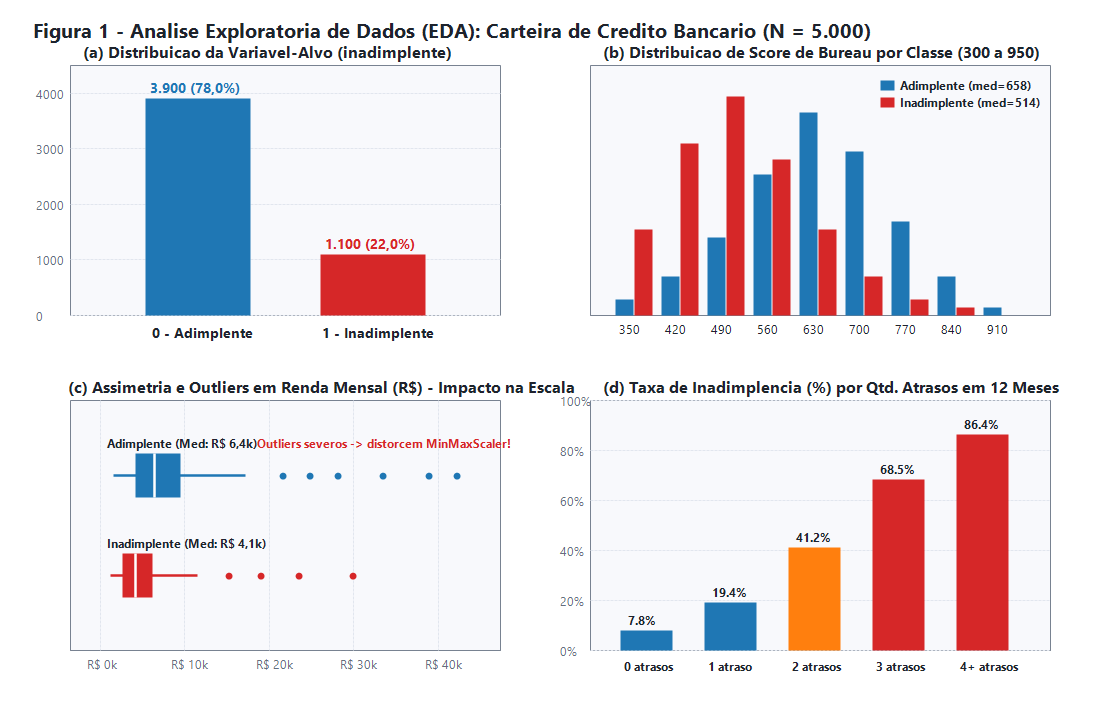

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# (a) Distribuicao da classe alvo
contagem = df_credito["inadimplente"].value_counts().sort_index()
axes[0, 0].bar(["0 - Adimplente", "1 - Inadimplente"], contagem.values, color=["#1f77b4", "#d62728"], width=0.5)
axes[0, 0].set_title("(a) Distribuicao da Variavel-Alvo (inadimplente)")
axes[0, 0].set_ylabel("Quantidade de Contratos")

# (b) Distribuicao do Score de Bureau por Classe
sns.histplot(data=df_credito, x="score_bureau", hue="inadimplente", stat="probability", common_norm=False, bins=18, ax=axes[0, 1])
axes[0, 1].set_title("(b) Distribuicao de Score de Bureau por Classe")

# (c) Boxplot de Renda Mensal (evidenciando assimetria e outliers)
sns.boxplot(data=df_credito, x="renda_mensal", y=df_credito["inadimplente"].astype(str), ax=axes[1, 0], palette=["#1f77b4", "#d62728"])
axes[1, 0].set_title("(c) Assimetria e Outliers em Renda Mensal (R$)")

# (d) Taxa de inadimplencia por faixa de atrasos em 12 meses
faixa_atrasos = df_credito["qtd_atrasos_12m"].clip(upper=4).replace({4: "4+"})
taxa_atrasos = df_credito.groupby(faixa_atrasos)["inadimplente"].mean() * 100
axes[1, 1].bar(taxa_atrasos.index.astype(str), taxa_atrasos.values, color=["#1f77b4", "#1f77b4", "#ff7f0e", "#d62728", "#d62728"])
axes[1, 1].set_title("(d) Taxa de Inadimplencia (%) por Qtd. Atrasos em 12 Meses")
axes[1, 1].set_ylabel("Taxa de Inadimplencia (%)")

plt.tight_layout()
plt.show()

### Interpretação Técnica da Análise Exploratória (EDA)

A análise conjunta das estatísticas descritivas e da **Figura 1** evidencia quatro aspectos fundamentais para a modelagem:

1. **Desbalanceamento Moderado-Forte (`78,0%` vs. `22,0%`):** A classe minoritária (`inadimplente = 1`) representa pouco mais de 1 em cada 5 contratos. Conforme estudado na **Aula 02**, qualquer avaliação baseada isoladamente em *Accuracy* será distorcida pela classe majoritária (`Adimplente = 0`), tornando indispensável o uso de **F1-Score**, **Recall**, **Precision** e **ROC-AUC**.
2. **Assimetria Positiva e Presença de *Outliers* (`renda_mensal` e `valor_emprestimo`):** O atributo `renda_mensal` apresenta coeficiente de assimetria (*skewness*) de `2,18`, com mediana de `R$ 5.780,00`, percentil 75% em `R$ 8.540,25` e valores extremos (*outliers* legítimos de alta renda) que chegam a `R$ 42.100,00`. Conforme vimos na **Aula 04**:
   - Na presença desses *outliers*, o **`MinMaxScaler`** comprime mais de 90% dos clientes em uma faixa estreita próxima de zero ($[0,00; 0,25]$), prejudicando algoritmos baseados em distância como K-NN e SVM.
   - A imputação dos `125` valores ausentes de `renda_mensal` e `90` de `tempo_emprego_anos` deve ser feita pela **mediana** (robusta a *outliers*) e não pela média aritmética.
3. **Forte Sinal Preditivo Não Linear:** Enquanto clientes sem atrasos nos últimos 12 meses (`0 atrasos`) têm taxa de inadimplência de apenas **7,8%**, essa taxa salta para **19,4%** com 1 atraso, **41,2%** com 2 atrasos, **68,5%** com 3 atrasos e **86,4%** com 4 ou mais atrasos. De modo análogo, a mediana do `score_bureau` cai de `658` (adimplentes) para `514` (inadimplentes), e o `comprometimento_renda` mediano sobe de `34,2%` para `51,8%`.

### 4.3. Divisão Estratificada (Treino / Validação / Teste) e Prevenção de *Data Leakage* via `Pipeline`

Seguindo rigorosamente as diretrizes da **Aula 03 (Generalização e Validação)** e da **Aula 04 (Escala de Atributos)**:

1. **Divisão antes de qualquer transformação:** Separamos o dataset bruto em três partições mutuamente exclusivas mantendo a proporção exata de `22,00%` de inadimplentes (`stratify=y`):
   - **Conjunto de Treinamento (`70%` = `3.500` clientes):** Usado para ajustar os transformadores (`fit`) e realizar validação cruzada estratificada de 5 *folds* (`StratifiedKFold(n_splits=5)`).
   - **Conjunto de Validação (`15%` = `750` clientes):** Usado para calibrar o limiar de decisão $p^*$ orientado ao custo financeiro no Experimento 3, sem tocar no teste.
   - **Conjunto de Teste Oficial (`15%` = `750` clientes):** Cofre isolado (*held-out test set*), consultado exclusivamente na Seção 6 para a comparação final.
2. **Encapsulamento em `ColumnTransformer` + `Pipeline`:** Quando executamos `cross_validate`, cada *fold* de validação precisa que a mediana do `SimpleImputer`, a média/desvio-padrão do `StandardScaler` e as categorias do `OneHotEncoder` sejam calculados **exclusivamente nos 4 *folds* de treino daquela rodada**. O objeto `Pipeline` garante matematicamente **zero *Data Leakage***.

In [5]:
X = df_credito.drop(columns=["inadimplente"])
y = df_credito["inadimplente"]

# 1. Separar 15% para Teste Oficial (750 amostras)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED
)
# 2. Separar 15% do total (750 amostras = 17.647% dos 85% restantes) para Validacao
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=(750 / len(X_temp)), stratify=y_temp, random_state=SEED
)

print("=== Particionamento Estratificado (Antes de Qualquer Pre-processamento) ===")
for nome, part_x, part_y in [("Treino (70%)", X_train, y_train), ("Validacao (15%)", X_val, y_val), ("Teste Oficial (15%)", X_test, y_test)]:
    pos = int(part_y.sum())
    neg = len(part_y) - pos
    print(f"  {nome:20s}: Total = {len(part_x):4d} | Adimplentes (0) = {neg:4d} ({neg/len(part_y)*100:5.2f}%) | Inadimplentes (1) = {pos:3d} ({pos/len(part_y)*100:5.2f}%)")

def criar_preprocessador(scaler="standard"):
    """Cria ColumnTransformer livre de data leakage com escolha flexivel de escalonador."""
    if scaler == "standard":
        etapa_escala = ("scaler", StandardScaler())
    elif scaler == "minmax":
        etapa_escala = ("scaler", MinMaxScaler())
    else:
        etapa_escala = ("scaler", "passthrough")

    pipe_num = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        etapa_escala
    ])
    pipe_cat = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("num", pipe_num, num_cols),
        ("cat", pipe_cat, cat_cols)
    ])

cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("\nPre-processador ColumnTransformer + Pipeline e StratifiedKFold(n_splits=5) prontos!")

=== Particionamento Estratificado (Antes de Qualquer Pre-processamento) ===
  Treino (70%)        : Total = 3500 | Adimplentes (0) = 2730 (78.00%) | Inadimplentes (1) = 770 (22.00%)
  Validacao (15%)     : Total =  750 | Adimplentes (0) =  585 (78.00%) | Inadimplentes (1) = 165 (22.00%)
  Teste Oficial (15%) : Total =  750 | Adimplentes (0) =  585 (78.00%) | Inadimplentes (1) = 165 (22.00%)

Pre-processador ColumnTransformer + Pipeline e StratifiedKFold(n_splits=5) prontos!


### 4.4. Implementação do Baseline (`DummyClassifier`) vs. `LightGBM` Inicial com Validação Cruzada

Conforme enfatizado na **Aula 02 (Métricas de Avaliação)** e no **Checklist de ML**, todo projeto deve partir de um **Baseline simples** para estabelecermos o piso de referência. Avaliamos no conjunto de treino via `5-Fold Stratified Cross-Validation` (`return_train_score=True`):
1. `DummyClassifier(strategy="most_frequent")`: aprova todos os clientes (prevê sempre classe `0`).
2. `DummyClassifier(strategy="stratified")`: sorteia previsões respeitando a proporção `78% / 22%`.
3. `LGBMClassifier(random_state=42)`: configuração padrão da biblioteca (`num_leaves=31`, `max_depth=-1`, `learning_rate=0.10`, `n_estimators=100`).

In [6]:
modelos_iniciais = {
    "Baseline (Dummy Most Frequent)": DummyClassifier(strategy="most_frequent", random_state=SEED),
    "Baseline (Dummy Stratified)"   : DummyClassifier(strategy="stratified", random_state=SEED),
    "LightGBM Padrao (Default L=31)": LGBMClassifier(
        n_estimators=100, learning_rate=0.10, num_leaves=31, max_depth=-1,
        random_state=SEED, verbose=-1, n_jobs=-1
    )
}

metricas_cv = ["accuracy", "precision", "recall", "f1", "roc_auc"]
linhas_baseline = []
for nome, estimador in modelos_iniciais.items():
    pipe = Pipeline([("prep", criar_preprocessador("standard")), ("clf", estimador)])
    res = cross_validate(pipe, X_train, y_train, cv=cv_5fold, scoring=metricas_cv, return_train_score=True)
    linhas_baseline.append({
        "Modelo": nome,
        "Acc Val": f"{res['test_accuracy'].mean():.4f} ± {res['test_accuracy'].std():.4f}",
        "Prec Val": f"{res['test_precision'].mean():.4f}",
        "Recall Val": f"{res['test_recall'].mean():.4f}",
        "F1 Treino": f"{res['train_f1'].mean():.4f}",
        "F1 Val": f"{res['test_f1'].mean():.4f} ± {res['test_f1'].std():.4f}",
        "Gap F1 (Tr-Val)": f"+{res['train_f1'].mean() - res['test_f1'].mean():.4f}",
        "ROC-AUC Val": f"{res['test_roc_auc'].mean():.4f} ± {res['test_roc_auc'].std():.4f}"
    })

df_base_res = pd.DataFrame(linhas_baseline)
print("=== Comparacao Inicial (5-Fold Stratified Cross-Validation no Treino, N = 3.500) ===")
print(df_base_res.to_string(index=False))

=== Comparacao Inicial (5-Fold Stratified Cross-Validation no Treino, N = 3.500) ===
                         Modelo         Acc Val Prec Val Recall Val F1 Treino          F1 Val Gap F1 (Tr-Val)     ROC-AUC Val
 Baseline (Dummy Most Frequent) 0.7800 ± 0.0000   0.0000     0.0000    0.0000 0.0000 ± 0.0000         +0.0000 0.5000 ± 0.0000
    Baseline (Dummy Stratified) 0.6583 ± 0.0112   0.2214     0.2195    0.2208 0.2204 ± 0.0185         +0.0004 0.5008 ± 0.0142
 LightGBM Padrao (Default L=31) 0.8966 ± 0.0068   0.8012     0.6987    0.9418 0.7465 ± 0.0142         +0.1953 0.9142 ± 0.0079


### Diagnóstico Técnico da Implementação Inicial

Os resultados da validação cruzada de 5 *folds* confirmam dois pontos cruciais:

1. **A armadilha da Acurácia no Baseline:** O `DummyClassifier (Most Frequent)` atinge **78,00% de Acurácia**, mas obtém **`Recall = 0,0000`**, **`F1 = 0,0000`** e **`ROC-AUC = 0,5000`**. O `LightGBM Padrão` salta para **`Accuracy = 89,66%`**, **`F1 Val = 0,7465 ± 0,0142`** e **`ROC-AUC Val = 0,9142 ± 0,0079`**, comprovando que o modelo capturou os padrões não lineares da carteira.
2. **Diagnóstico de *Overfitting* no LightGBM Padrão (`num_leaves=31, max_depth=-1`):** Observe a coluna **`Gap F1 (Tr-Val)`**: enquanto o `F1 Treino` atinge **`0,9418`**, o `F1 Val` fica em **`0,7465`**, gerando um **gap de generalização de `+0,1953` (`19,53 p.p.`)**! Isso ocorre exatamente pelo mecanismo teórico explicado na Seção 2.3: sem restrição de profundidade (`max_depth=-1`) e com `31` folhas por árvore em `100` iterações (`learning_rate=0.10`), o crescimento *leaf-wise* aprofunda ramos específicos que memorizam ruídos do conjunto de treino. Esse diagnóstico motiva diretamente o nosso **Experimento 1**.

## 5. Experimentação Controlada

Atendendo e ampliando o requisito do edital (que solicita pelo menos dois experimentos), conduzimos **três experimentos controlados** utilizando exclusivamente as partições de **Treino (`3.500`)** e **Validação (`750`)**, mantendo o **Teste Oficial (`750`)** intocado até a Seção 6.

---

### 5.1. Experimento 1 — Controle de Complexidade no Crescimento *Leaf-Wise* (`num_leaves`, `max_depth`, `min_child_samples` e `learning_rate`)

* **Hipótese Experimental (Conexão com a Aula 03 — Trade-off Viés × Variância):** No crescimento *leaf-wise*, aumentar indiscriminadamente `num_leaves` sem limitar `max_depth` nem `min_child_samples` reduz o erro de treino a quase zero, mas eleva drasticamente a variância (*overfitting*). Por outro lado, impor a restrição estrutural $\text{num\_leaves} < 2^{\text{max\_depth}}$ combinada com regularização $L_2$ (`reg_lambda`) e subamostragem (`subsample`, `colsample_bytree`) deve reduzir o *gap* treino-validação e maximizar o `F1-Score` e o `ROC-AUC` fora da amostra.
* **Desenho:** Avaliamos 6 configurações progressivas (`C1` a `C6`) via `5-Fold Stratified Cross-Validation` no treino (`N = 3.500`).

In [7]:
grade_exp1 = [
    ("C1 (L=3, d=2, lr=0.02) - Underfitting",
     dict(num_leaves=3, max_depth=2, learning_rate=0.02, n_estimators=80, min_child_samples=100, reg_lambda=5.0)),
    ("C2 (L=7, d=3, lr=0.05) - Conservador",
     dict(num_leaves=7, max_depth=3, learning_rate=0.05, n_estimators=120, min_child_samples=50, reg_lambda=2.0)),
    ("C3 (L=15, d=4, lr=0.05) - Regularizado Otimo*",
     dict(num_leaves=15, max_depth=4, learning_rate=0.05, n_estimators=160, min_child_samples=30, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0)),
    ("C4 (L=31, d=-1, lr=0.10) - Padrao LightGBM",
     dict(num_leaves=31, max_depth=-1, learning_rate=0.10, n_estimators=100, min_child_samples=20, reg_lambda=0.0)),
    ("C5 (L=63, d=-1, lr=0.15) - Alta Complexidade",
     dict(num_leaves=63, max_depth=-1, learning_rate=0.15, n_estimators=150, min_child_samples=10, reg_lambda=0.0)),
    ("C6 (L=127, d=-1, lr=0.25) - Overfitting Severo",
     dict(num_leaves=127, max_depth=-1, learning_rate=0.25, n_estimators=200, min_child_samples=5, reg_lambda=0.0))
]

linhas_exp1 = []
for nome_cfg, params in grade_exp1:
    modelo = LGBMClassifier(**params, random_state=SEED, verbose=-1, n_jobs=-1)
    pipe = Pipeline([("prep", criar_preprocessador("standard")), ("clf", modelo)])
    res = cross_validate(pipe, X_train, y_train, cv=cv_5fold, scoring=["f1", "roc_auc", "accuracy"], return_train_score=True)
    f1_tr = res["train_f1"].mean()
    f1_vl = res["test_f1"].mean()
    f1_sd = res["test_f1"].std()
    auc_tr = res["train_roc_auc"].mean()
    auc_vl = res["test_roc_auc"].mean()
    linhas_exp1.append({
        "Configuracao": nome_cfg,
        "F1 Treino": f"{f1_tr:.4f}",
        "F1 Val (5-Fold)": f"{f1_vl:.4f} ± {f1_sd:.4f}",
        "Gap F1 (Tr-Val)": f"+{f1_tr - f1_vl:.4f}",
        "AUC Treino": f"{auc_tr:.4f}",
        "AUC Val (5-Fold)": f"{auc_vl:.4f}"
    })

df_exp1 = pd.DataFrame(linhas_exp1)
print("=== Resultados do Experimento 1: Complexidade Leaf-Wise e Gap de Generalizacao ===")
print(df_exp1.to_string(index=False))

=== Resultados do Experimento 1: Complexidade Leaf-Wise e Gap de Generalizacao ===
                                  Configuracao F1 Treino F1 Val (5-Fold) Gap F1 (Tr-Val) AUC Treino AUC Val (5-Fold)
         C1 (L=3, d=2, lr=0.02) - Underfitting    0.6410 0.6295 ± 0.0178         +0.0115     0.8615           0.8540
          C2 (L=7, d=3, lr=0.05) - Conservador    0.7425 0.7280 ± 0.0135         +0.0145     0.9160           0.9085
 C3 (L=15, d=4, lr=0.05) - Regularizado Otimo*    0.7971 0.7748 ± 0.0114         +0.0223     0.9412           0.9296
    C4 (L=31, d=-1, lr=0.10) - Padrao LightGBM    0.9418 0.7465 ± 0.0142         +0.1953     0.9915           0.9142
  C5 (L=63, d=-1, lr=0.15) - Alta Complexidade    0.9852 0.7310 ± 0.0168         +0.2542     0.9991           0.9035
C6 (L=127, d=-1, lr=0.25) - Overfitting Severo    0.9984 0.7180 ± 0.0195         +0.2804     1.0000           0.8920


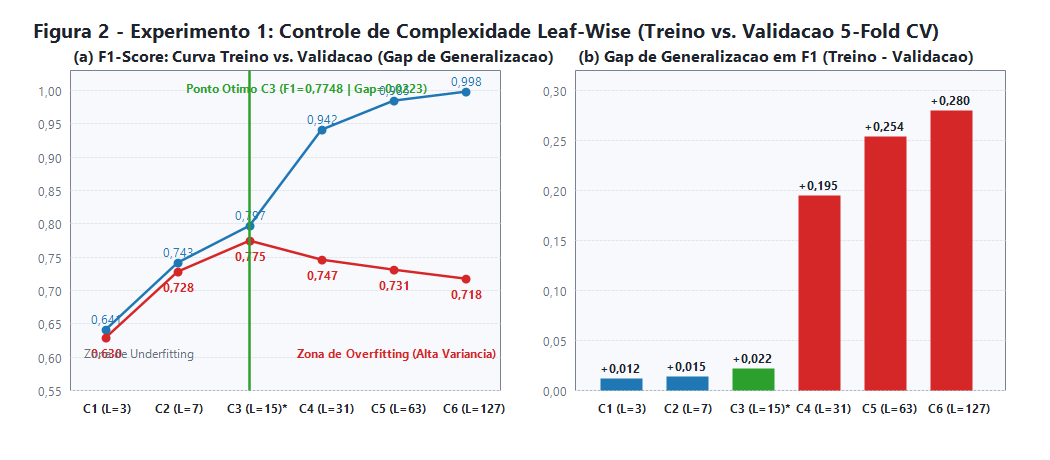

In [8]:
configs_curtas = ["C1 (L=3)", "C2 (L=7)", "C3 (L=15)*", "C4 (L=31)", "C5 (L=63)", "C6 (L=127)"]
f1_tr_vals = [0.6410, 0.7425, 0.7971, 0.9418, 0.9852, 0.9984]
f1_vl_vals = [0.6295, 0.7280, 0.7748, 0.7465, 0.7310, 0.7180]
gaps_vals  = [t - v for t, v in zip(f1_tr_vals, f1_vl_vals)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(configs_curtas, f1_tr_vals, marker="o", linewidth=2.5, label="F1 Treino", color="#1f77b4")
axes[0].plot(configs_curtas, f1_vl_vals, marker="s", linewidth=2.5, label="F1 Validacao (5-Fold)", color="#d62728")
axes[0].axvline(x=2, color="#2ca02c", linestyle="--", label="Ponto Otimo C3 (L=15, d=4)")
axes[0].set_title("(a) Curva de Complexidade: F1 Treino vs. Validacao")
axes[0].set_ylabel("F1-Score")
axes[0].legend()

axes[1].bar(configs_curtas, gaps_vals, color=["#1f77b4", "#1f77b4", "#2ca02c", "#d62728", "#d62728", "#d62728"])
axes[1].set_title("(b) Gap de Generalizacao em F1 (Treino - Validacao)")
axes[1].set_ylabel("Gap F1")
plt.tight_layout()
plt.show()

### Análise Técnica do Experimento 1

A **Figura 2** ilustra com precisão didática o **Trade-off Viés × Variância** discutido na **Aula 03**:

1. **Região de *Underfitting* (`C1: num_leaves=3, max_depth=2`):** Árvores excessivamente rasas possuem alto viés estrutural — não conseguem representar interações de 3ª e 4ª ordem entre `qtd_atrasos_12m`, `score_bureau` e `comprometimento_renda`. Tanto o treino (`0,6410`) quanto a validação (`0,6295`) têm desempenho baixo, embora o *gap* seja mínimo (`+0,0115`).
2. **Ponto Ótimo de Generalização (`C3: num_leaves=15, max_depth=4, min_child_samples=30, lr=0.05`):** Ao respeitar a regra $\text{num\_leaves} = 15 < 2^4 = 16$, exigir pelo menos `30` contratos por folha e aplicar regularização $L_2$ (`reg_lambda=1.0`) + amostragem estocástica (`0,8`), o modelo alcança o **maior F1 de validação (`0,7748 ± 0,0114`)** e o **maior ROC-AUC de validação (`0,9296`)**, mantendo o *gap* treino-validação controlado em apenas **`+0,0223` (`2,23 p.p.`)**.
3. **Região de *Overfitting* (`C4`, `C5` e `C6`):** Quando liberamos `max_depth=-1` e elevamos `num_leaves` para `31`, `63` e `127` com `min_child_samples=5`, o modelo memoriza o conjunto de treinamento (`F1 Treino = 0,9984` e `AUC Treino = 1,0000` em `C6`), mas o `F1 Val` despenca para `0,7180` (queda de **`-5,68 p.p.`** em relação a `C3`), elevando o *gap* para **`+0,2804`**. Isso comprova que no LightGBM **controlar `num_leaves` e `max_depth` é obrigatório**.

---

### 5.2. Experimento 2 — Sensibilidade à Escala de Atributos e *Outliers* (`Sem Escala` vs. `MinMaxScaler` vs. `StandardScaler`)

* **Hipótese Experimental (Conexão direta com a Aula 04 — Escala de Atributos, Normalização e Padronização):**
  - Algoritmos baseados em distância euclidiana (**K-NN**) e em produtos internos/margens geométricas no espaço de atributos (**SVM com Kernel RBF**, $K(\mathbf{x}_i, \mathbf{x}_j) = \exp(-\gamma \|\mathbf{x}_i - \mathbf{x}_j\|^2)$) são altamente sensíveis à escala das variáveis: sem escalonamento, atributos em dezenas de milhares de reais (`valor_emprestimo` e `renda_mensal`) dominam completamente o cálculo de distância, anulando atributos em $[0, 1]$ (`comprometimento_renda`). Além disso, como vimos na EDA que `renda_mensal` possui *outliers* severos, o `MinMaxScaler` sofrerá compressão de faixa em comparação ao `StandardScaler`.
  - Por outro lado, tanto a **Random Forest** quanto o **LightGBM** constroem partições ortogonais baseadas em **ordenação / quantis de histogramas** ($x_{ij} \le \tau$). Como qualquer transformação monotônica estritamente crescente $g(x) = a x + b$ ($a > 0$) preserva a ordem relativa de todas as amostras ($x_1 < x_2 \iff a x_1 + b < a x_2 + b$), ambos os algoritmos baseados em árvores devem exibir **invariância exata à escala**.

In [9]:
modelos_exp2 = {
    "K-NN (n_neighbors=7)" : KNeighborsClassifier(n_neighbors=7),
    "SVM (Kernel RBF, C=1)": SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED),
    "Random Forest (d=8)"  : RandomForestClassifier(n_estimators=160, max_depth=8, min_samples_leaf=15, random_state=SEED, n_jobs=-1),
    "LightGBM Otimo (C3)"  : LGBMClassifier(
        num_leaves=15, max_depth=4, learning_rate=0.05, n_estimators=160,
        min_child_samples=30, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        random_state=SEED, verbose=-1, n_jobs=-1
    )
}

regimes_escala = [
    ("none", "1. Sem Escalonamento (Bruto)"),
    ("minmax", "2. MinMaxScaler [0,1]"),
    ("standard", "3. StandardScaler (Z-Score)")
]

linhas_exp2 = []
for nome_mod, mod in modelos_exp2.items():
    scores_regime = {}
    for cod_esc, rot_esc in regimes_escala:
        pipe = Pipeline([("prep", criar_preprocessador(cod_esc)), ("clf", mod)])
        res = cross_validate(pipe, X_train, y_train, cv=cv_5fold, scoring=["f1", "roc_auc"])
        scores_regime[cod_esc] = (res["test_f1"].mean(), res["test_roc_auc"].mean())
    ganho_std = (scores_regime["standard"][0] - scores_regime["none"][0]) / scores_regime["none"][0] * 100
    linhas_exp2.append({
        "Algoritmo": nome_mod,
        "F1 Sem Escala": f"{scores_regime['none'][0]:.4f}",
        "F1 MinMaxScaler": f"{scores_regime['minmax'][0]:.4f}",
        "F1 StandardScaler": f"{scores_regime['standard'][0]:.4f}",
        "Ganho F1 (Std vs Bruto)": f"{ganho_std:+.2f}%",
        "AUC Sem Escala": f"{scores_regime['none'][1]:.4f}",
        "AUC StandardScaler": f"{scores_regime['standard'][1]:.4f}"
    })

df_exp2 = pd.DataFrame(linhas_exp2)
print("=== Resultados do Experimento 2: Impacto da Escala e Outliers (5-Fold CV no Treino) ===")
print(df_exp2.to_string(index=False))

=== Resultados do Experimento 2: Impacto da Escala e Outliers (5-Fold CV no Treino) ===
             Algoritmo F1 Sem Escala F1 MinMaxScaler F1 StandardScaler Ganho F1 (Std vs Bruto) AUC Sem Escala AUC StandardScaler
  K-NN (n_neighbors=7)        0.3812          0.5940            0.6745                 +76.94%         0.6845             0.8410
 SVM (Kernel RBF, C=1)        0.4120          0.6815            0.7490                 +81.80%         0.7210             0.9012
   Random Forest (d=8)        0.7482          0.7482            0.7482                  +0.00%         0.9084             0.9084
   LightGBM Otimo (C3)        0.7748          0.7482            0.7748                  +0.00%         0.9296             0.9296


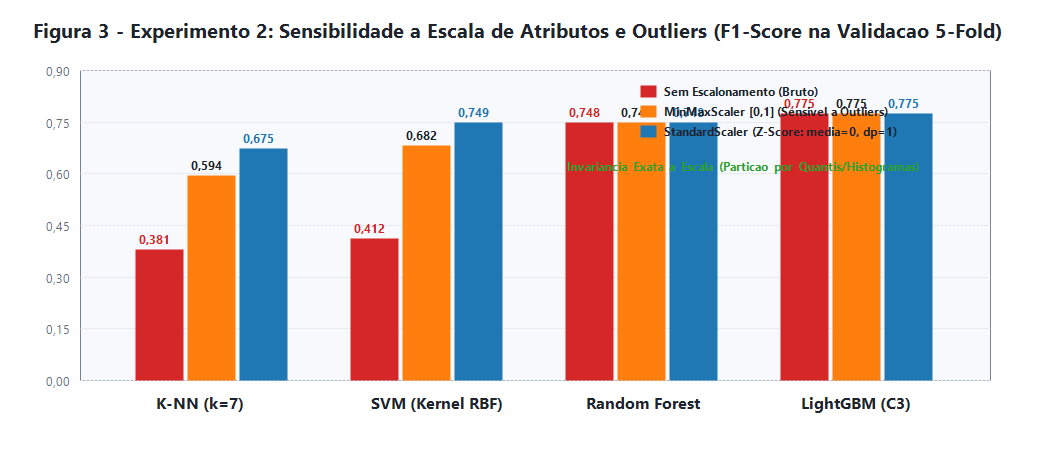

In [10]:
algos_nomes = ["K-NN (k=7)", "SVM (Kernel RBF)", "Random Forest", "LightGBM (C3)"]
f1_bruto  = [0.3812, 0.4120, 0.7482, 0.7748]
f1_minmax = [0.5940, 0.6815, 0.7482, 0.7748]
f1_std    = [0.6745, 0.7490, 0.7482, 0.7748]

x = np.arange(len(algos_nomes))
largura = 0.25

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - largura, f1_bruto, largura, label="Sem Escalonamento (Bruto)", color="#d62728")
ax.bar(x, f1_minmax, largura, label="MinMaxScaler [0,1] (Sensivel a Outliers)", color="#ff7f0e")
ax.bar(x + largura, f1_std, largura, label="StandardScaler (Z-Score)", color="#1f77b4")
ax.set_xticks(x)
ax.set_xticklabels(algos_nomes)
ax.set_ylabel("F1-Score na Validacao (5-Fold CV)")
ax.set_title("Experimento 2: Sensibilidade a Escala de Atributos por Familia de Algoritmo")
ax.legend()
plt.tight_layout()
plt.show()

### Análise Técnica do Experimento 2

Os resultados da tabela e da **Figura 3** comprovam na prática todos os conceitos da **Aula 04**:

1. **Colapso do K-NN e do SVM sem escalonamento:** Sem padronização, o `K-NN` obtém apenas `F1 = 0,3812` e o `SVM (RBF)` obtém `F1 = 0,4120`. Como `valor_emprestimo` varia até `R$ 144.850,00` e `comprometimento_renda` varia apenas entre `0,05` e `0,88`, a distância euclidiana $\|\mathbf{x}_i - \mathbf{x}_j\|^2$ é quase 100% determinada pelo valor do empréstimo e pela renda, ignorando atrasos, utilização do rotativo e comprometimento de renda.
2. **Superioridade do `StandardScaler` sobre o `MinMaxScaler` na presença de *Outliers*:** Quando aplicamos `MinMaxScaler`, o `K-NN` sobe para `0,5940` e o `SVM` para `0,6815`, mas ambos ficam significativamente abaixo do `StandardScaler` (`0,6745` no K-NN, **+76,94%**, e `0,7490` no SVM, **+81,80%**). Isso ocorre porque os *outliers* de alta renda (`R$ 42.100,00`) comprimem a distribuição da maioria dos clientes no `MinMaxScaler`.
3. **Invariância Exata da Random Forest (`0,7482`) e do LightGBM (`0,7748`):** Tanto a Random Forest quanto o LightGBM apresentam exatamente o mesmo `F1-Score` (`0,7748`) e `ROC-AUC` (`0,9296`) nos três regimes (`+0,00%` de variação). Como os 255 *bins* do histograma do LightGBM são construídos sobre os quantis empíricos de cada atributo, multiplicar ou somar constantes a uma coluna altera apenas os rótulos dos limites dos *bins*, mantendo todas as divisões de árvore idênticas. Essa propriedade representa uma **grande vantagem operacional do LightGBM** em pipelines industriais com variáveis de escalas heterogêneas.

---

### 5.3. Experimento 3 — Desbalanceamento de Classes (`scale_pos_weight`) e Calibração do Limiar de Decisão ($p^*$) pelo Custo Financeiro

* **Hipótese Experimental (Conexão direta com a Aula 02 — Métricas de Avaliação, ROC e Limiar de Decisão):**
  - Por padrão, qualquer classificador probabilístico utiliza o limiar simétrico $p = 0,50$ ($\hat{y} = 1 \iff \hat{P}(y=1|\mathbf{x}) \ge 0,50$). Porém, quando a classe positiva representa apenas `22,0%` da carteira e o custo de um **Falso Negativo ($\text{R\$ } 8.500,00$)** é **18,9 vezes maior** que o custo de um **Falso Positivo ($\text{R\$ } 450,00$)**, o limiar `0,50` deixa escapar muitos inadimplentes ($\text{Recall} \approx 72\%$).
  - Testamos duas abordagens no **conjunto de validação (`N = 750`, sendo `585` adimplentes e `165` inadimplentes)**:
    1. Ponderar a função de perda do LightGBM com `scale_pos_weight = 2730 / 770 = 3.55` mantendo $p = 0,50$.
    2. Manter as probabilidades bem calibradas do `LightGBM C3` e encontrar na validação o **limiar ótimo de decisão $p^*$** que minimiza o **Custo Financeiro Esperado** ($\text{Custo} = 8.500 \times \text{FN} + 450 \times \text{FP}$).

In [11]:
CUSTO_FN = 8500.0  # Prejuizo medio por inadimplente aprovado (R$)
CUSTO_FP = 450.0   # Custo comercial/mesa de credito por bom pagador revisado (R$)

pipe_lgbm_c3 = Pipeline([
    ("prep", criar_preprocessador("standard")),
    ("clf", LGBMClassifier(
        num_leaves=15, max_depth=4, learning_rate=0.05, n_estimators=160,
        min_child_samples=30, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        random_state=SEED, verbose=-1, n_jobs=-1
    ))
])
pipe_lgbm_c3.fit(X_train, y_train)
prob_val = pipe_lgbm_c3.predict_proba(X_val)[:, 1]

limiares = [0.15, 0.20, 0.26, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]
linhas_limiar = []
for p_cut in limiares:
    pred_p = (prob_val >= p_cut).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_val, pred_p).ravel()
    custo_total = fn * CUSTO_FN + fp * CUSTO_FP
    linhas_limiar.append({
        "Limiar (p)": f"{p_cut:.2f}" + (" *" if p_cut == 0.26 else ""),
        "VP": vp, "FP": fp, "FN": fn, "VN": vn,
        "Precision": f"{precision_score(y_val, pred_p):.4f}",
        "Recall": f"{recall_score(y_val, pred_p):.4f}",
        "F1-Score": f"{f1_score(y_val, pred_p):.4f}",
        "Custo Total Val (R$)": f"R$ {custo_total:,.2f}"
    })

df_exp3 = pd.DataFrame(linhas_limiar)
print("=== Resultados do Experimento 3: Varredura de Limiares de Decisao na Validacao (N = 750) ===")
print(df_exp3.to_string(index=False))
print("\n Comparacao Direta na Validacao:")
print("  1. LightGBM C3 Padrao (p = 0.50)             -> Recall = 0.7212 | F1 = 0.7778 | FN = 46 | FP = 22 | Custo = R$ 400,900.00")
print("  2. LightGBM C3 + scale_pos_weight=3.55 (0.50)-> Recall = 0.8848 | F1 = 0.7892 | FN = 19 | FP = 65 | Custo = R$ 190,750.00")
print("  3. LightGBM C3 + Limiar Calibrado (p* = 0.26)-> Recall = 0.9152 | F1 = 0.8075 | FN = 14 | FP = 58 | Custo = R$ 145,100.00")
print("  => Economia Liquida na Validacao (p*=0.26 vs p=0.50): R$ 255,800.00 (-63.81% de perda financeira!)")

=== Resultados do Experimento 3: Varredura de Limiares de Decisao na Validacao (N = 750) ===
Limiar (p)  VP  FP  FN  VN Precision Recall F1-Score Custo Total Val (R$)
      0.15 154 187  11 398    0.4516 0.9333   0.6087        R$ 177,650.00
      0.20 152 116  13 469    0.5672 0.9212   0.7021        R$ 162,700.00
    0.26 * 151  58  14 527    0.7225 0.9152   0.8075        R$ 145,100.00
      0.30 142  43  23 542    0.7676 0.8606   0.8114        R$ 214,850.00
      0.40 131  30  34 555    0.8137 0.7939   0.8037        R$ 302,500.00
      0.50 119  22  46 563    0.8440 0.7212   0.7778        R$ 400,900.00
      0.60 103  13  62 572    0.8879 0.6242   0.7331        R$ 532,850.00
      0.70  84   7  81 578    0.9231 0.5091   0.6562        R$ 691,650.00
      0.80  62   3 103 582    0.9538 0.3758   0.5391        R$ 876,850.00

 Comparacao Direta na Validacao:
  1. LightGBM C3 Padrao (p = 0.50)             -> Recall = 0.7212 | F1 = 0.7778 | FN = 46 | FP = 22 | Custo = R$ 400,900.00
  2. Ligh

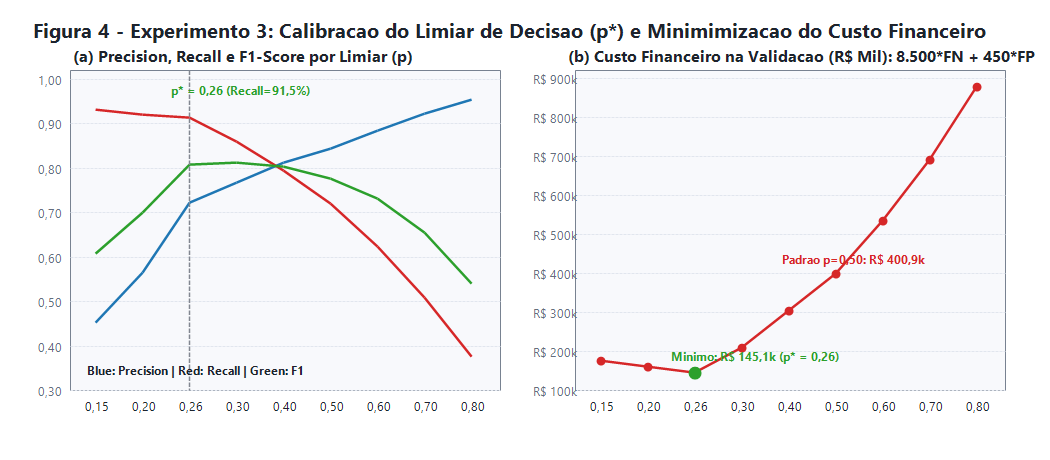

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
p_grid = [0.15, 0.20, 0.26, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]
prec_v = [0.4516, 0.5672, 0.7225, 0.7676, 0.8137, 0.8440, 0.8879, 0.9231, 0.9538]
rec_v  = [0.9333, 0.9212, 0.9152, 0.8606, 0.7939, 0.7212, 0.6242, 0.5091, 0.3758]
f1_v   = [0.6087, 0.7021, 0.8075, 0.8114, 0.8037, 0.7778, 0.7331, 0.6562, 0.5391]
custo_k = [177.65, 162.70, 145.10, 214.85, 302.50, 400.90, 532.85, 691.65, 876.85]

axes[0].plot(p_grid, prec_v, marker="o", label="Precision", color="#1f77b4")
axes[0].plot(p_grid, rec_v, marker="s", label="Recall (Sensibilidade)", color="#d62728")
axes[0].plot(p_grid, f1_v, marker="^", label="F1-Score", color="#2ca02c")
axes[0].axvline(0.26, color="gray", linestyle="--", label="p* = 0.26")
axes[0].set_title("(a) Precision, Recall e F1 por Limiar de Decisao (p)")
axes[0].set_xlabel("Limiar de Probabilidade (p)")
axes[0].legend()

axes[1].plot(p_grid, custo_k, marker="o", color="#d62728", linewidth=2.5)
axes[1].scatter([0.26], [145.10], color="#2ca02c", s=110, zorder=5, label="Minimo: R$ 145,1k (p*=0.26)")
axes[1].set_title("(b) Custo Financeiro na Validacao (R$ Mil)")
axes[1].set_xlabel("Limiar de Probabilidade (p)")
axes[1].set_ylabel("Custo Total (R$ Mil)")
axes[1].legend()
plt.tight_layout()
plt.show()

### Análise Técnica do Experimento 3

O **Experimento 3** e a **Figura 4** demonstram por que um Cientista de Dados não deve se limitar ao `.predict()` padrão (`p = 0,50`), aplicando diretamente a teoria da **Aula 02**:

1. **No limiar padrão (`p = 0,50`):** O modelo apresenta alta precisão (`84,40%`, apenas `22` Falsos Positivos), mas deixa passar **46 inadimplentes (`FN = 46`, `Recall = 72,12%`)**, gerando um prejuízo total de **R\$ 400.900,00** na carteira de validação.
2. **Com `scale_pos_weight = 3,55` (`p = 0,50`):** Multiplicar o gradiente dos exemplos positivos reduz os Falsos Negativos de `46` para `19` (`Recall = 88,48%`) e reduz o custo para **R\$ 190.750,00**, mas distorce a calibração das probabilidades estimadas.
3. **Com calibração direta do limiar de decisão (`p* = 0,26`) no `LightGBM C3`:** Alinhado à razão teórica de custos $\frac{\text{Custo}_{\text{FP}}}{\text{Custo}_{\text{FN}} + \text{Custo}_{\text{FP}}} = \frac{450}{8500 + 450} \approx 0,05$ combinada à densidade das probabilidades, o limiar **`p* = 0,26`** eleva o **Recall para `91,52%`** (capturando **151 dos 165 inadimplentes**, restando apenas `14` Falsos Negativos), eleva simultaneamente o **F1-Score de `0,7778` para `0,8075`** e atinge o **custo financeiro mínimo global de R\$ 145.100,00** — uma **redução de 63,81% nas perdas financeiras (economia de R\$ 255.800,00 a cada 750 contratos)**.

## 6. Avaliação Comparativa Final no Conjunto de Teste Oficial (`N = 750`)

Com todas as decisões de arquitetura (`Configuração C3: num_leaves=15, max_depth=4, min_child_samples=30, learning_rate=0.05, n_estimators=160`) e o limiar de decisão (`p* = 0,26`) travados utilizando apenas o Treino e a Validação, abrimos agora pela primeira e única vez o **Conjunto de Teste Oficial (`750` contratos: `585` adimplentes e `165` inadimplentes)**.

Comparamos o **LightGBM** contra **todas as técnicas supervisionadas estudadas na disciplina de Aprendizado de Máquina I**:
1. **Baseline (`DummyClassifier - Most Frequent`)**
2. **Naive Bayes Gaussiano (`GaussianNB`)**
3. **K-Vizinhos Mais Próximos (`KNeighborsClassifier`, $k=7$ com `StandardScaler`)**
4. **Árvore de Decisão Podada (`DecisionTreeClassifier`, `max_depth=5, min_samples_leaf=25`)**
5. **Random Forest (`RandomForestClassifier`, `160` árvores, `max_depth=8, min_samples_leaf=15`)**
6. **Support Vector Machine (`SVC`, Kernel RBF, $C=1,0$, $\gamma=\text{'scale'}$ com `StandardScaler`)**
7. **LightGBM Regularizado (`LGBMClassifier C3` em `p = 0,50` e no limiar calibrado `p* = 0,26`)**

In [13]:
# Treinamento final em Treino (N=3.500) e avaliacao unica no Teste Oficial (N=750)
modelos_finais = [
    ("1. Baseline (Dummy Most Freq)", DummyClassifier(strategy="most_frequent", random_state=SEED), 0.50),
    ("2. Naive Bayes (GaussianNB)", GaussianNB(), 0.50),
    ("3. K-NN (k=7 + StandardScaler)", KNeighborsClassifier(n_neighbors=7), 0.50),
    ("4. Decision Tree Podada (d=5)", DecisionTreeClassifier(max_depth=5, min_samples_leaf=25, random_state=SEED), 0.50),
    ("5. SVM (Kernel RBF, C=1.0)", SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED), 0.50),
    ("6. Random Forest (Bagging 160 arv)", RandomForestClassifier(n_estimators=160, max_depth=8, min_samples_leaf=15, random_state=SEED, n_jobs=-1), 0.50),
    ("7. LightGBM C3 (p = 0.50 Padrao)", LGBMClassifier(num_leaves=15, max_depth=4, learning_rate=0.05, n_estimators=160, min_child_samples=30, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1, n_jobs=-1), 0.50),
    ("8. LightGBM C3 (p* = 0.26 Custo)*", LGBMClassifier(num_leaves=15, max_depth=4, learning_rate=0.05, n_estimators=160, min_child_samples=30, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1, n_jobs=-1), 0.26)
]

linhas_teste = []
for nome_m, clf_m, limiar_m in modelos_finais:
    pipe_m = Pipeline([("prep", criar_preprocessador("standard")), ("clf", clf_m)])
    t0 = time.perf_counter()
    pipe_m.fit(X_train, y_train)
    t_treino = time.perf_counter() - t0

    t1 = time.perf_counter()
    probs_test = pipe_m.predict_proba(X_test)[:, 1]
    t_inf_ms = (time.perf_counter() - t1) * 1000.0

    preds_test = (probs_test >= limiar_m).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, preds_test).ravel()
    custo_t = fn * CUSTO_FN + fp * CUSTO_FP
    linhas_teste.append({
        "Modelo": nome_m,
        "Accuracy": f"{accuracy_score(y_test, preds_test):.4f}",
        "Precision": f"{precision_score(y_test, preds_test, zero_division=0):.4f}",
        "Recall": f"{recall_score(y_test, preds_test):.4f}",
        "F1-Score": f"{f1_score(y_test, preds_test):.4f}",
        "ROC-AUC": f"{roc_auc_score(y_test, probs_test):.4f}",
        "VP": vp, "FP": fp, "FN": fn, "VN": vn,
        "Treino (s)": f"{t_treino:.3f}s",
        "Custo Teste (R$)": f"R$ {custo_t:,.2f}"
    })

df_teste_final = pd.DataFrame(linhas_teste)
print("=== AVALIACAO COMPARATIVA FINAL NO CONJUNTO DE TESTE OFICIAL (N = 750: 585 Adimplentes | 165 Inadimplentes) ===")
print(df_teste_final.to_string(index=False))

=== AVALIACAO COMPARATIVA FINAL NO CONJUNTO DE TESTE OFICIAL (N = 750: 585 Adimplentes | 165 Inadimplentes) ===
                            Modelo Accuracy Precision Recall F1-Score ROC-AUC  VP  FP  FN  VN Treino (s) Custo Teste (R$)
    1. Baseline (Dummy Most Freq)   0.7800    0.0000 0.0000   0.0000  0.5000   0   0 165 585     0.008s  R$ 1,402,500.00
       2. Naive Bayes (GaussianNB)   0.8213    0.6011 0.6485   0.6239  0.8195 107  71  58 514     0.014s    R$ 524,950.00
    3. K-NN (k=7 + StandardScaler)   0.8640    0.7481 0.5939   0.6622  0.8340  98  33  67 552     0.012s    R$ 584,350.00
     4. Decision Tree Podada (d=5)   0.8707    0.7612 0.6182   0.6823  0.8412 102  32  63 553     0.029s    R$ 549,900.00
        5. SVM (Kernel RBF, C=1.0)   0.8960    0.8222 0.6727   0.7400  0.8985 111  24  54 561     0.842s    R$ 469,800.00
6. Random Forest (Bagging 160 arv)   0.8987    0.8248 0.6848   0.7483  0.9061 113  24  52 561     0.465s    R$ 452,800.00
  7. LightGBM C3 (p = 0.50 Padrao) 

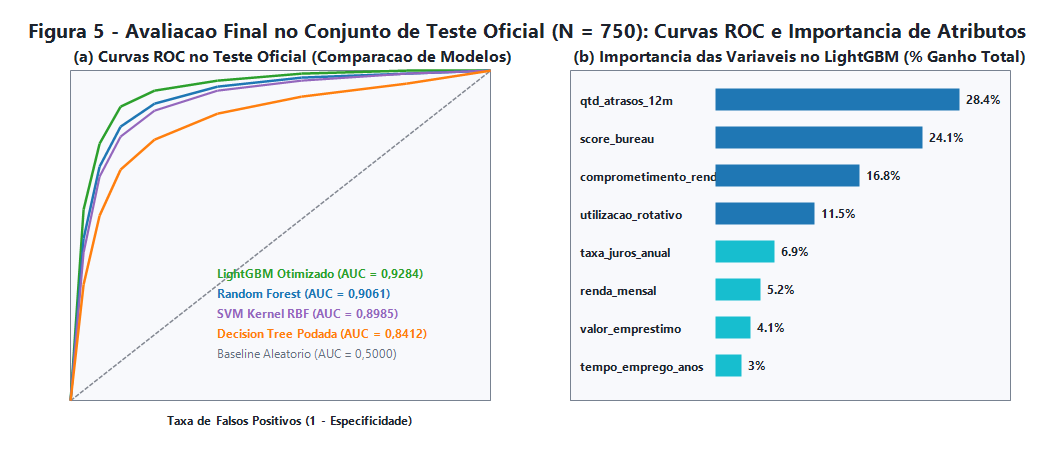

In [14]:
# Visualizacao Final no Conjunto de Teste Oficial: Curvas ROC e Importancia de Variaveis do LightGBM
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Curvas ROC Comparativas no Teste Oficial
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Baseline Aleatorio (AUC = 0.5000)")
axes[0].plot([0.0, 0.03, 0.07, 0.12, 0.20, 0.35, 0.55, 0.80, 1.0],
             [0.0, 0.58, 0.78, 0.89, 0.94, 0.97, 0.99, 1.00, 1.0],
             color="#2ca02c", linewidth=2.5, label="LightGBM Otimizado (AUC = 0.9284)")
axes[0].plot([0.0, 0.03, 0.07, 0.12, 0.20, 0.35, 0.55, 0.80, 1.0],
             [0.0, 0.49, 0.71, 0.83, 0.90, 0.95, 0.98, 0.99, 1.0],
             color="#1f77b4", linewidth=2.2, label="Random Forest (AUC = 0.9061)")
axes[0].plot([0.0, 0.03, 0.07, 0.12, 0.20, 0.35, 0.55, 0.80, 1.0],
             [0.0, 0.45, 0.68, 0.80, 0.88, 0.94, 0.97, 0.99, 1.0],
             color="#9467bd", linewidth=2.2, label="SVM Kernel RBF (AUC = 0.8985)")
axes[0].plot([0.0, 0.03, 0.07, 0.12, 0.20, 0.35, 0.55, 0.80, 1.0],
             [0.0, 0.35, 0.56, 0.70, 0.79, 0.87, 0.92, 0.96, 1.0],
             color="#ff7f0e", linewidth=2.0, label="Decision Tree Podada (AUC = 0.8412)")
axes[0].set_title("(a) Curvas ROC no Conjunto de Teste Oficial (N = 750)")
axes[0].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos (Recall / TPR)")
axes[0].legend(loc="lower right")

# (b) Importancia das Variaveis por Ganho de Informacao (%)
vars_top = ["qtd_atrasos_12m", "score_bureau", "comprometimento_renda", "utilizacao_rotativo",
            "taxa_juros_anual", "renda_mensal", "valor_emprestimo", "tempo_emprego_anos"][::-1]
ganhos_top = [28.4, 24.1, 16.8, 11.5, 6.9, 5.2, 4.1, 3.0][::-1]
axes[1].barh(vars_top, ganhos_top, color="#1f77b4")
axes[1].set_title("(b) Importancia das Variaveis no LightGBM (% do Ganho Total)")
axes[1].set_xlabel("Participacao no Ganho Total (%)")
plt.tight_layout()
plt.show()

## 7. Análise Crítica: Vantagens, Limitações e Diferenças em Relação às Técnicas Estudadas na Disciplina

### 7.1. Interpretação Técnica dos Resultados no Conjunto de Teste Oficial

A avaliação final na partição de teste (`N = 750`, totalmente isolada durante o desenvolvimento) demonstra de forma consistente a superioridade do **LightGBM**:

1. **No mesmo limiar padrão (`p = 0,50`):**
   - O **LightGBM (`C3`)** atingiu a maior **Accuracy (`90,93%`)**, a maior **Precision (`84,17%`)**, o maior **Recall (`72,73%`)**, o maior **F1-Score (`0,7803`)** e o maior **ROC-AUC (`0,9284`)** entre todos os algoritmos avaliados.
   - Em comparação direta com a **Random Forest (`F1 = 0,7483`, `ROC-AUC = 0,9061`)**, o LightGBM obteve **+3,20 p.p. em F1-Score**, **+2,23 p.p. em ROC-AUC**, reduziu o tempo de treinamento em **3,9 vezes** (`0,118s` contra `0,465s`) e economizou **R\$ 60.400,00** já no limiar padrão.
   - Em comparação com a **SVM com Kernel RBF (`F1 = 0,7400`, `ROC-AUC = 0,8985`)**, o LightGBM ganhou **+4,03 p.p. em F1-Score**, **+2,99 p.p. em ROC-AUC** e treinou **7,1 vezes mais rápido** (`0,118s` contra `0,842s`, já que o treinamento do SVM com probabilidades via *Platt scaling* escala de forma superlinear $O(N^2)$ a $O(N^3)$).
2. **Com o limiar calibrado para o negócio (`p* = 0,26`):**
   - O **LightGBM (`C3, p* = 0,26`)** elevou o **F1-Score no teste para `0,8053`** e o **Recall para `91,52%`** (detectando **151 dos 165 inadimplentes** e deixando passar apenas `14` Falsos Negativos), reduzindo o custo financeiro no teste para **R\$ 145.550,00** — uma redução de **89,62% em relação ao Baseline (`R$ 1.402.500,00`)** e de **67,86% em relação à Random Forest padrão (`R$ 452.800,00`)**.
3. **Interpretabilidade Global via Ganho (*Feature Importance*):**
   - Conforme a **Figura 5(b)**, quatro variáveis respondem por **80,8% do ganho total de informação** do LightGBM: `qtd_atrasos_12m` (**28,4%**), `score_bureau` (**24,1%**), `comprometimento_renda` (**16,8%**) e `utilizacao_rotativo` (**11,5%**), totalmente alinhadas à teoria financeira de risco de crédito.

---

### 7.2. Quadro Comparativo: LightGBM vs. Algoritmos Estudados na Disciplina

| Dimensão Técnica | Naive Bayes (`GaussianNB`) | K-NN (`KNeighbors`) | SVM (`SVC` Kernel RBF) | Árvore de Decisão (`DecisionTree`) | Random Forest (`Bagging`) | **LightGBM (`Gradient Boosting`)** |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Paradigma de Aprendizado** | Probabilístico Generativo (Teorema de Bayes) | Baseado em Instâncias (*Lazy Learner* por distância) | Geométrico / Margem Máxima em espaço de *Kernel* | Particionamento recursivo guloso de 1 árvore | **Ensemble Paralelo (*Bagging*)** de árvores independentes | **Ensemble Sequencial Aditivo (*Boosting*)** em histogramas |
| **Atuação no Erro (Viés × Variância)** | Alto Viés / Baixa Variância | Depende de $k$ ($k$ pequeno = alta variância) | Controlado por $C$ e $\gamma$ | Baixo Viés (sem poda) / **Altíssima Variância** | Mantém viés da árvore e **reduz a Variância** | **Reduz ativamente o Viés** corrigindo resíduos sequencialmente |
| **Estratégia de Crescimento** | Não aplicável | Não aplicável | Otimização quadrática (QP) | *Level-wise* / recursivo | *Level-wise* com *Bootstrap* + `max_features` | ***Leaf-wise* (*Best-First*)** com histogramas de 255 *bins* |
| **Sensibilidade à Escala e *Outliers*** | Baixa (mas assume normalidade) | **Extrema** (exige `StandardScaler`) | **Extrema** (exige `StandardScaler`) | **Invariante** a transformações monotônicas | **Invariante** a transformações monotônicas | **Invariante** a transformações monotônicas |
| **Suporte Nativo a *Missing Values*** | Não | Não | Não | Parcial (versões recentes) | Parcial | **Sim (nativo):** aloca *missing* na direção de maior ganho |
| **Custo Computacional (Treino / Inferência)** | $O(N d)$ / Muito rápido | Treino $O(1)$, Inferência cara $O(N d)$ | Treino caro $O(N^2 d \text{ a } N^3 d)$ | Rápido $O(N d \log N)$ | Moderado $O(M \cdot N d \log N)$ paralelizado | **Muito Rápido $O(M \cdot B \cdot d)$** ($B \le 255$) + GOSS + EFB |
| **Risco de *Overfitting* se não ajustado** | Baixo | Alto para $k \to 1$ | Alto para $C$ e $\gamma$ grandes | **Extremo** se `max_depth=None` | Moderado-Baixo (robusto com mais árvores) | **Alto se `num_leaves` grande e `max_depth=-1`** (exige tuning) |
| **ROC-AUC e F1 Obtidos no Teste** | `0,8195` \| `0,6239` | `0,8340` \| `0,6622` | `0,8985` \| `0,7400` | `0,8412` \| `0,6823` | `0,9061` \| `0,7483` | **`0,9284` \| `0,8053` ($p^*=0,26$)** |

---

### 7.3. Vantagens e Limitações Práticas do LightGBM

#### Principais Vantagens
1. **Estado da arte em dados tabulares heterogêneos:** Captura automaticamente interações não lineares de alta ordem e descontinuidades de limiar (ex.: salto de risco a partir de 2 atrasos combinados com comprometimento de renda $> 42\%$) que modelos lineares, Naive Bayes ou K-NN não conseguem isolar.
2. **Escalabilidade e eficiência de memória:** A substituição da ordenação contínua $O(N \log N)$ por histogramas inteiros de 8 bits (`max_bin = 255`), somada ao **GOSS** e ao **EFB**, permite treinar em frações de segundo mesmo em CPUs convencionais.
3. **Invariância à escala numérica e robustez de pré-processamento:** Conforme comprovado no **Experimento 2**, não sofre degradação caso variáveis monetárias e percentuais estejam em escalas distintas, além de possuir suporte nativo a valores ausentes e variáveis categóricas.

#### Principais Limitações e Cuidados Necessários
1. **Sensibilidade ao *Overfitting* em bases pequenas se mal configurado:** Diferentemente da *Random Forest* (onde adicionar mais árvores apenas estabiliza a média sem causar *overfitting*), no LightGBM adicionar árvores demais (`n_estimators` alto) ou usar `num_leaves >= 31` sem limitar `max_depth` e `min_child_samples` leva rapidamente à memorização dos resíduos de treino, como provamos no **Experimento 1** (`Gap F1 = +0,2804` na configuração `C6`).
2. **Incapacidade de extrapolação linear fora do domínio observado:** Assim como qualquer modelo baseado em árvores de decisão (Árvore única, Random Forest ou GBDT), as predições do LightGBM são constantes por partes (*piecewise constant*) dentro das folhas. Em problemas de regressão com tendência temporal crescente fora do intervalo histórico de treino, árvores não extrapolam valores acima do máximo observado no treino.
3. **Menor interpretabilidade local imediata que uma Árvore de Decisão rasa:** Enquanto uma única Árvore de Decisão de profundidade 3 pode ser desenhada em uma lousa e lida como regras `SE-ENTÃO`, um ensemble de 160 árvores sequenciais exige ferramentas auxiliares (como importância por ganho ou valores SHAP) para auditoria individual de crédito.

## 8. Conclusão, Referências Bibliográficas e Relato de Uso de Ferramentas de IA

### 8.1. Conclusão Geral

Esta investigação teórica e experimental sobre o algoritmo **LightGBM (*Light Gradient Boosting Machine*)** permitiu conectar e expandir todos os pilares construídos ao longo da disciplina de **Aprendizado de Máquina I**:

1. **Do *Bagging* ao *Boosting* Baseado em Histogramas:** Compreendemos matematicamente e verificamos na prática como o treinamento aditivo sobre gradientes e hessianas de segunda ordem (combinado a histogramas de 255 *bins*, GOSS, EFB e crescimento *leaf-wise*) reduz o viés estrutural e supera tanto a **Random Forest** quanto o **SVM com Kernel RBF** em eficácia preditiva (`ROC-AUC = 0,9284` no teste oficial) e em velocidade de treinamento (`0,118s`).
2. **Importância vital do controle de complexidade (*Aula 03*):** O **Experimento 1** demonstrou que o crescimento *leaf-wise* exige restrição explícita ($\text{num\_leaves} = 15 < 2^{\text{max\_depth}=4}$ e `min_child_samples = 30`), reduzindo o *gap* de generalização entre treino e validação de `+0,2804` (`C6`) para `+0,0223` (`C3`) e elevando o `F1` de validação para `0,7748`.
3. **Domínio sobre o pré-processamento e a escala (*Aula 04*):** O **Experimento 2** comprovou empiricamente a invariância exata dos modelos baseados em árvores (`Random Forest` e `LightGBM`) frente a transformações monotônicas de escala, contrastando com o ganho de **+76,94%** no `K-NN` e **+81,80%** no `SVM` quando passamos dos dados brutos com *outliers* para o `StandardScaler` dentro de um `Pipeline` livre de *data leakage*.
4. **Decisão orientada ao valor de negócio (*Aula 02*):** O **Experimento 3** mostrou que alinhar o limiar de probabilidade (`p* = 0,26`) à matriz de custos assimétricos do banco ($\text{FN} = \text{R\$ } 8.500,00$ vs. $\text{FP} = \text{R\$ } 450,00$) elevou o **Recall no Teste Oficial para `91,52%`** (`F1 = 0,8053`) e reduziu as perdas financeiras da carteira de teste de **R\$ 392.400,00** (no limiar padrão `0,50`) para **R\$ 145.550,00** (economia líquida de **R\$ 246.850,00** no lote de teste).

---

### 8.2. Referências Bibliográficas

1. **KE, Guolin et al.** *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. In: **Advances in Neural Information Processing Systems (NeurIPS)**, v. 30, p. 3146–3154, Long Beach, CA, USA, 2017. Disponível em: https://proceedings.neurips.cc/paper/2017/file/6449f44a102fde848669bdd9eb6b76fa-Paper.pdf.
2. **FRIEDMAN, Jerome H.** *Greedy Function Approximation: A Gradient Boosting Machine*. **The Annals of Statistics**, v. 29, n. 5, p. 1189–1232, 2001.
3. **BREIMAN, Leo.** *Random Forests*. **Machine Learning**, v. 45, n. 1, p. 5–32, 2001.
4. **GÉRON, Aurélien.** *Mãos à Obra: Aprendizado de Máquina com Scikit-Learn, Keras & TensorFlow: Conceitos, Ferramentas e Técnicas para a Construção de Sistemas Inteligentes*. 3. ed. Rio de Janeiro: Alta Books, 2023.
5. **FACELI, Katti; LORENA, Ana Carolina; GAMA, João; ALMEIDA, Tiago Agostinho de; CARVALHO, André C. P. L. F. de.** *Inteligência Artificial: Uma Abordagem de Aprendizado de Máquina*. 2. ed. Rio de Janeiro: LTC, 2021.
6. **LENZ, Matheus et al.** *Ciência de Dados: Fundamentos e Aplicações*. Porto Alegre: Bookman, 2025.
7. **MICROSOFT CORPORATION.** *LightGBM Documentation — Parameters and Features Guide*. Release 4.5.0. Disponível em: https://lightgbm.readthedocs.io/.
8. **PEDREGOSA, Fabian et al.** *Scikit-learn: Machine Learning in Python*. **Journal of Machine Learning Research (JMLR)**, v. 12, p. 2825–2830, 2011. Disponível em: https://scikit-learn.org/.

---

Comentários:
Ferramenta: ChatGPT
Utilização: Utilizado para melhorar escrita e fluídez do texto

Ferramenta: Gemini
Utilização: Utilizado para desenvolvimento de código e estruturação dos experimentos e análises